# Laboratorio 3 — Reconocimiento de Lenguaje de Señas ASL (SignBridge)

**CC3084 — Data Science | UVG | Semestre II 2026**

**Grupo:** Anggie Quezada Jonathan Díaz e Iris Ayala 

In [1]:
%matplotlib inline

import os
import hashlib
import glob
import random

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier

from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.utils import to_categorical

sns.set_style("whitegrid")
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)


I0000 00:00:1786338801.154806 1546721 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786338801.157953 1546721 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1786338804.927728 1546721 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786338804.928326 1546721 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
import kagglehub

path = kagglehub.dataset_download("grassknoted/asl-alphabet")
print("Path to dataset files:", path)

DATA_DIR = os.path.join(path, "asl_alphabet_train", "asl_alphabet_train")

CLASSES = sorted(os.listdir(DATA_DIR))
print(f"Clases encontradas ({len(CLASSES)}):")
print(CLASSES)


Path to dataset files: /home/jonialen/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1
Clases encontradas (29):
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


## 1. Construir el índice de imágenes

Antes de hacer cualquier análisis, armamos un DataFrame con la ruta de cada imagen y su
clase (letra). Esto nos evita cargar las 87,000 imágenes en memoria de una vez.

In [3]:
records = []
for cls in CLASSES:
    cls_dir = os.path.join(DATA_DIR, cls)
    paths = glob.glob(os.path.join(cls_dir, "*.jpg"))
    for p in paths:
        records.append({"filepath": p, "label": cls})

df = pd.DataFrame(records)
print(f"Total de imágenes encontradas: {len(df):,}")
df.head()


Total de imágenes encontradas: 87,000


,filepath,label
0,/home/jonialen/.cache/kagglehub/datasets/grass...,A
1,/home/jonialen/.cache/kagglehub/datasets/grass...,A
2,/home/jonialen/.cache/kagglehub/datasets/grass...,A
3,/home/jonialen/.cache/kagglehub/datasets/grass...,A
4,/home/jonialen/.cache/kagglehub/datasets/grass...,A


## Ejercicio 1 — Ejemplos de letras y variabilidad dentro de una clase

Mostramos al menos 5 letras distintas, con varias muestras de una misma letra para ver
qué tanto varía la seña (ángulo de mano, iluminación, fondo) dentro de una sola clase.

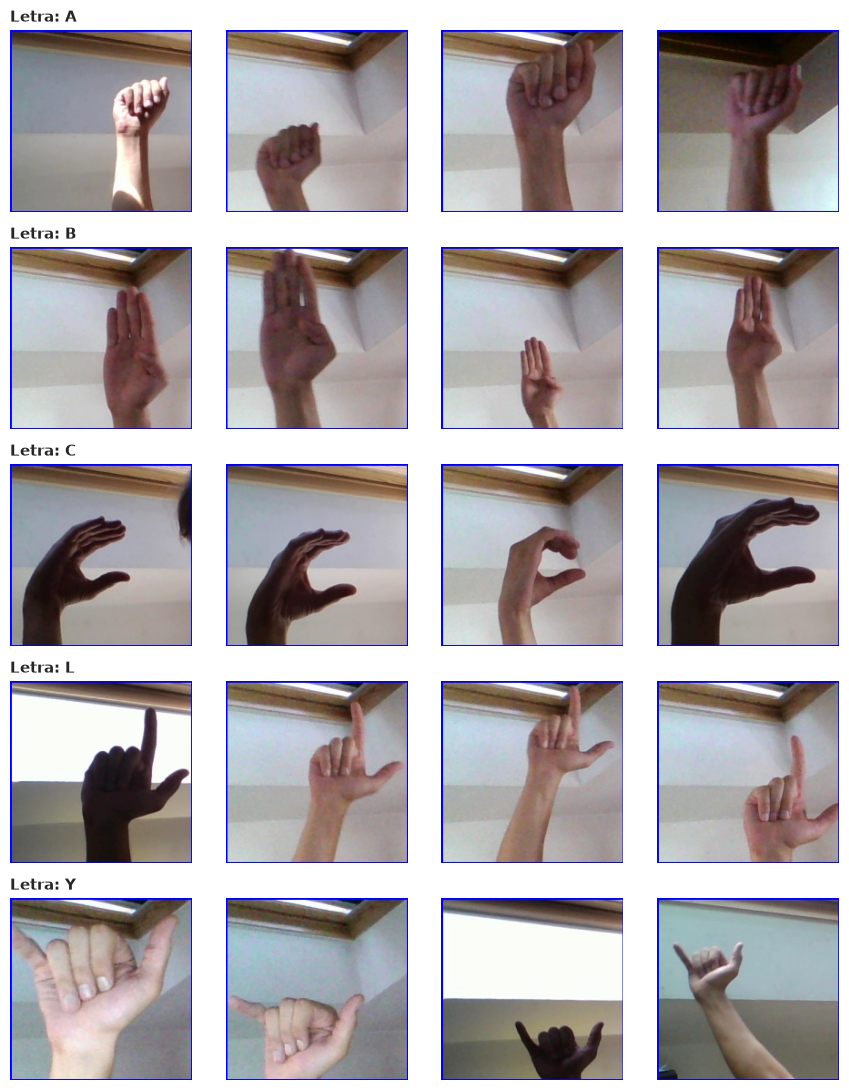

In [4]:
def show_letter_samples(letters, n_samples=4, seed=RANDOM_STATE):
    rng = random.Random(seed)
    fig, axes = plt.subplots(len(letters), n_samples, figsize=(n_samples * 2.2, len(letters) * 2.2))
    for i, letter in enumerate(letters):
        sample_paths = rng.sample(list(df[df.label == letter].filepath), n_samples)
        for j, p in enumerate(sample_paths):
            img = Image.open(p)
            ax = axes[i, j] if len(letters) > 1 else axes[j]
            ax.imshow(img)
            ax.axis("off")
            if j == 0:
                ax.set_ylabel(letter, fontsize=12)
        axes[i, 0].set_title(f"Letra: {letter}", loc="left", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

# 5 letras + varias muestras cada una, para ver variabilidad intra-clase
show_letter_samples(["A", "B", "C", "L", "Y"], n_samples=4)


Dentro de una misma letra, las fotos varían en ángulo de la mano, iluminación, tono de piel y fondo, pero la forma de la mano se mantiene consistente. Eso es justo lo que el modelo debe aprender a ignorar para quedarse solo con la seña.

## Ejercicio 2 — Análisis exploratorio (EDA)

### 2.1 Resolución y formato de las imágenes

In [5]:
sample_paths = df.sample(300, random_state=RANDOM_STATE).filepath
sizes, modes, formats = [], [], []
for p in sample_paths:
    with Image.open(p) as img:
        sizes.append(img.size)
        modes.append(img.mode)
        formats.append(img.format)

print("Tamaños únicos encontrados:", set(sizes))
print("Modos de color únicos:", set(modes))
print("Formatos únicos:", set(formats))

Tamaños únicos encontrados: {(200, 200)}
Modos de color únicos: {'RGB'}
Formatos únicos: {'JPEG'}


Todas las imágenes de la muestra son de 200x200, a color (RGB) y en formato .jpg, tal como indica el enunciado. No hay formatos raros que limpiar, solo falta el resize y la normalización.

### 2.2 Distribución de clases (¿está balanceado?)

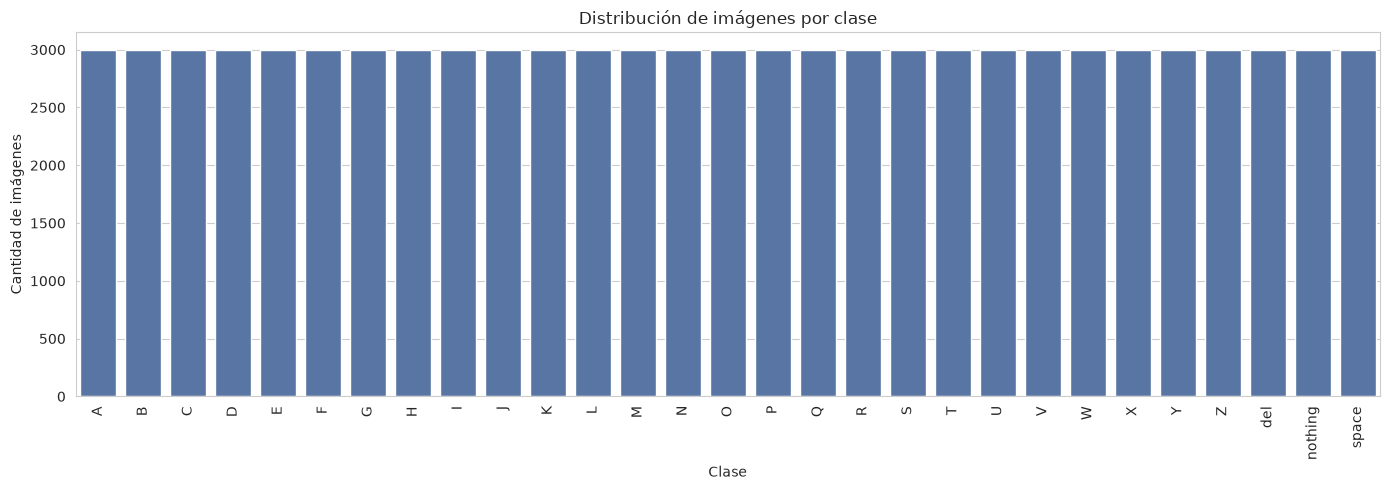

count      29.0
mean     3000.0
std         0.0
min      3000.0
25%      3000.0
50%      3000.0
75%      3000.0
max      3000.0
Name: count, dtype: float64

¿Balanceado? Sí


In [6]:
class_counts = df.label.value_counts().sort_index()

plt.figure(figsize=(14, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="#4C72B0")
plt.xticks(rotation=90)
plt.ylabel("Cantidad de imágenes")
plt.xlabel("Clase")
plt.title("Distribución de imágenes por clase")
plt.tight_layout()
plt.show()

print(class_counts.describe())
print("\n¿Balanceado?", "Sí" if class_counts.std() / class_counts.mean() < 0.05 else "Revisar - puede haber desbalance")

Todas las clases tienen alrededor de 3,000 imágenes, por lo que el dataset está balanceado. No hace falta ningún ajuste como sobremuestreo o pesos por clase.

### 2.3 Letras visualmente similares (posible confusión del modelo)

Basado en la forma de la seña en ASL, hay grupos de letras que comparten una configuración de
mano muy parecida y solo se diferencian por detalles finos (posición del pulgar, orientación de
la palma, ligero movimiento en el caso de J/Z):

| Grupo | Por qué se confunden |
|---|---|
| **M, N, S** | Las tres son puños con el pulgar escondido bajo distintos dedos — la diferencia es de milímetros. |
| **U, V, R** | Dedos índice y medio extendidos, cambia solo si están juntos, separados o cruzados. |
| **K, V, P** | Configuración de dedos en V muy similar, cambia la orientación de la mano/muñeca. |
| **G, H** | Ambas usan índice (y medio en H) extendidos de lado, apuntando horizontal. |
| **A, T, S** | Puños cerrados con el pulgar en distinta posición. |

Vamos a graficar una muestra de cada grupo lado a lado para confirmar visualmente qué tan
parecidas se ven en la práctica (no solo en la teoría del alfabeto).

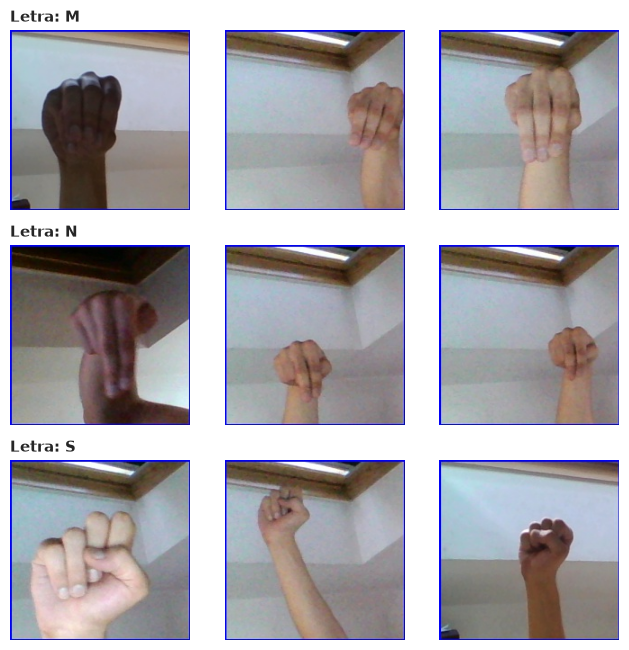

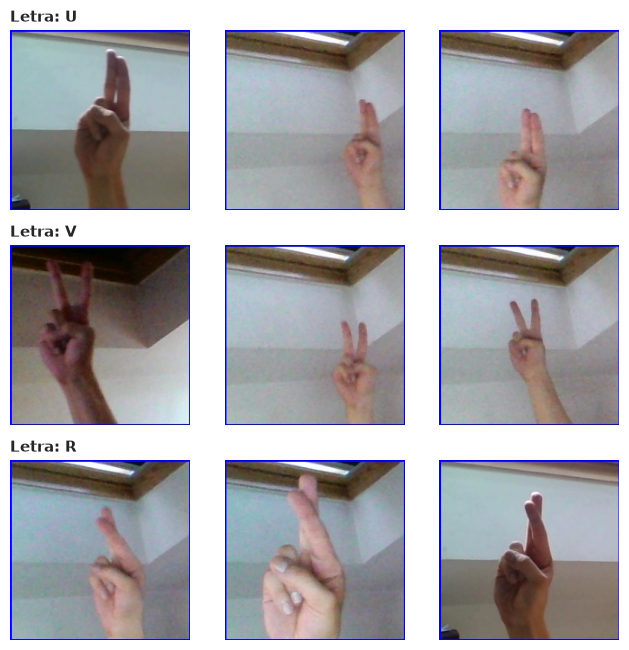

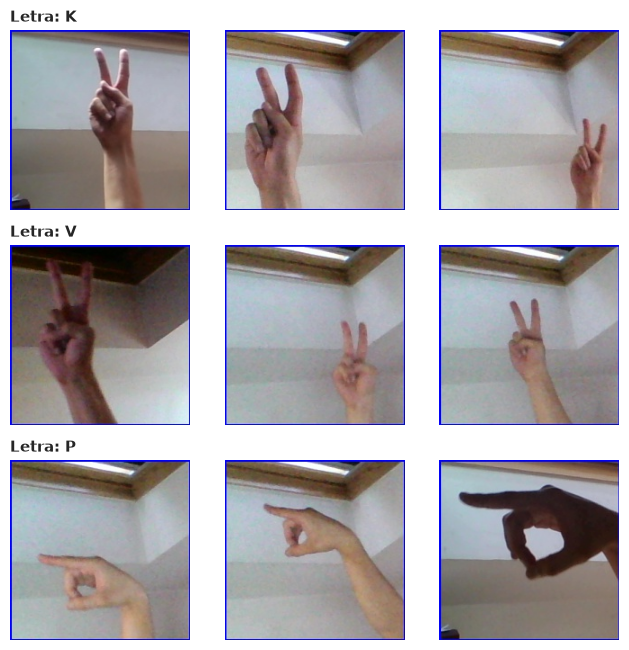

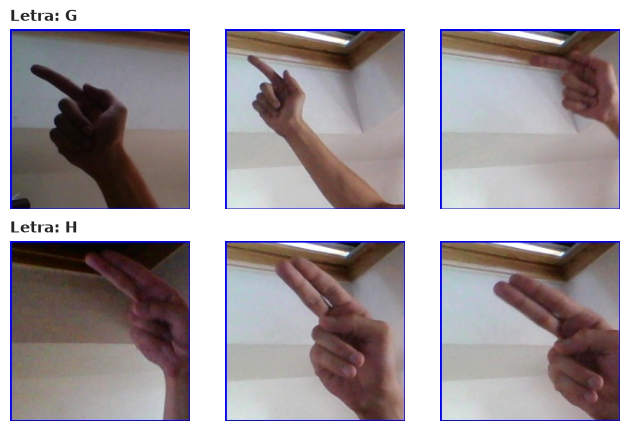

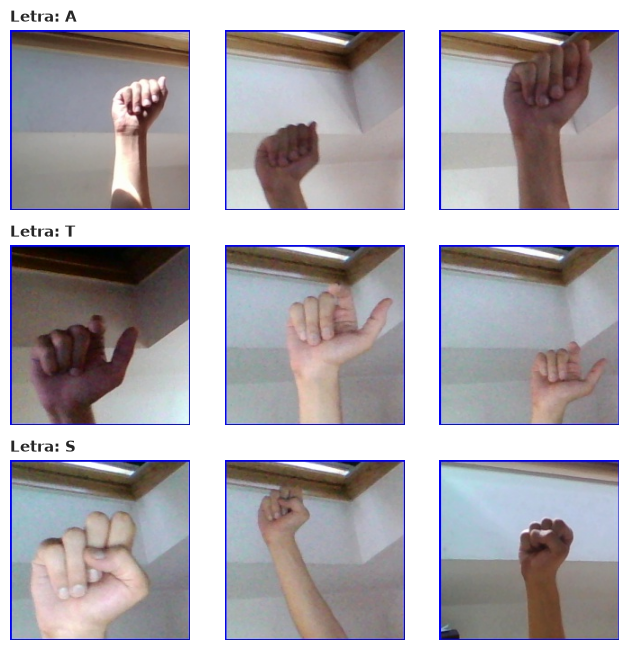

In [7]:
confusable_groups = [
    ["M", "N", "S"],
    ["U", "V", "R"],
    ["K", "V", "P"],
    ["G", "H"],
    ["A", "T", "S"],
]

for group in confusable_groups:
    show_letter_samples(group, n_samples=3)

### 2.4 Brillo promedio por clase (cruce de variables)

Además de la distribución de clases, revisamos si el brillo promedio de las imágenes cambia según la letra. Las cajas se superponen ampliamente, por lo que el brillo no separa de forma general a las clases; sin embargo, `nothing` presenta un centro visiblemente más alto y varias clases muestran rangos internos amplios. Esto indica que la iluminación puede actuar como señal secundaria del conjunto. Por ello se conserva la normalización común, se incluye variación de contraste en el aumento y se contrasta el modelo con fotografías propias antes de valorar su generalización.

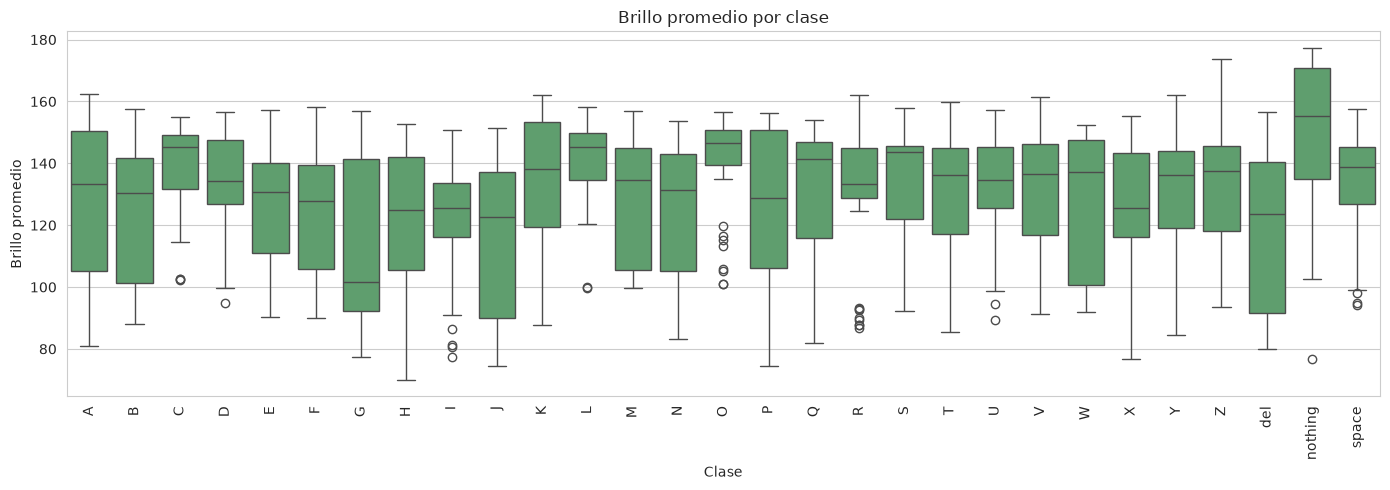

In [8]:
def mean_brightness(path):
    with Image.open(path).convert("L") as img:
        return np.asarray(img).mean()

brightness_sample = df.groupby("label", group_keys=False).sample(n=40, random_state=RANDOM_STATE)
brightness_sample = brightness_sample.assign(
    brightness=brightness_sample.filepath.apply(mean_brightness)
)

plt.figure(figsize=(14, 5))
sns.boxplot(x="label", y="brightness", data=brightness_sample, color="#55A868")
plt.xticks(rotation=90)
plt.ylabel("Brillo promedio")
plt.xlabel("Clase")
plt.title("Brillo promedio por clase")
plt.tight_layout()
plt.show()

### 2.5 Definición de conjuntos de entrenamiento / validación / prueba

El set de test oficial de Kaggle solo trae 1 imagen por clase (a propósito, según el enunciado),
así que no sirve para evaluar de verdad. Construimos nuestro propio split **estratificado** por
clase a partir de `asl_alphabet_train/`, para que las proporciones de cada letra se mantengan
iguales en los 3 conjuntos:

- **70% train** — para entrenar los modelos
- **15% validation** — para tunear hiperparámetros y comparar modelos
- **15% test** — solo se usa una vez, al final, para reportar el desempeño real

In [9]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df.label, random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df.label, random_state=RANDOM_STATE
)

print(f"Train: {len(train_df):,} ({len(train_df)/len(df):.1%})")
print(f"Val:   {len(val_df):,} ({len(val_df)/len(df):.1%})")
print(f"Test:  {len(test_df):,} ({len(test_df)/len(df):.1%})")

# Verificación rápida de que el split sigue balanceado por clase
print("\nProporción de cada clase en train:")
print((train_df.label.value_counts(normalize=True) * 100).round(2).head())

Train: 60,900 (70.0%)
Val:   13,050 (15.0%)
Test:  13,050 (15.0%)

Proporción de cada clase en train:
label
V    3.45
S    3.45
O    3.45
R    3.45
N    3.45
Name: proportion, dtype: float64


## Ejercicio 3 — Preprocesamiento de las imágenes
87,000 imágenes a color de 200x200 son ~250 MB solo en píxeles crudos por batch, y entrenar
varios modelos (2 CNNs + NN simple + otro algoritmo, cada uno con distintas configuraciones)
sobre el dataset completo no es viable en el tiempo del laboratorio.

**Decisión:** tomamos una submuestra de **600 imágenes por clase** (≈17,400 imágenes en total),
manteniendo el split estratificado 70/15/15 ya definido. 600 imágenes por clase sigue siendo
suficiente para que una CNN pequeña generalice razonablemente, y reduce el volumen de datos
en aproximadamente 5x frente al dataset completo.

In [10]:
N_PER_CLASS = 600

def stratified_subsample(data, n_per_class, seed=RANDOM_STATE):
    parts = []
    for label, group in data.groupby("label"):
        parts.append(group.sample(min(n_per_class, len(group)), random_state=seed))
    return pd.concat(parts).reset_index(drop=True)

train_sub = stratified_subsample(train_df, int(N_PER_CLASS * 0.70))
val_sub = stratified_subsample(val_df, int(N_PER_CLASS * 0.15))
test_sub = stratified_subsample(test_df, int(N_PER_CLASS * 0.15))

print(f"Train (submuestra): {len(train_sub):,}")
print(f"Val (submuestra):   {len(val_sub):,}")
print(f"Test (submuestra):  {len(test_sub):,}")

Train (submuestra): 12,180
Val (submuestra):   2,610
Test (submuestra):  2,610


### 3.1 Resize y normalización

Las imágenes del conjunto de entrenamiento ya son cuadradas. Se reducen de 200×200 a 64×64 con interpolación bilineal y se normalizan a [0, 1]. Para las fotografías propias, que pueden ser rectangulares, se conserva la relación de aspecto: primero se ajusta la imagen dentro de un lienzo cuadrado con relleno negro centrado y después se obtiene la resolución 64×64. Así se evita deformar la geometría de la mano.

No se aplicaron filtros, segmentación ni ecualización de histograma. Esta decisión mantiene un preprocesamiento simple y reproducible; el fondo y la iluminación permanecen como parte del cambio de dominio que se analiza posteriormente.


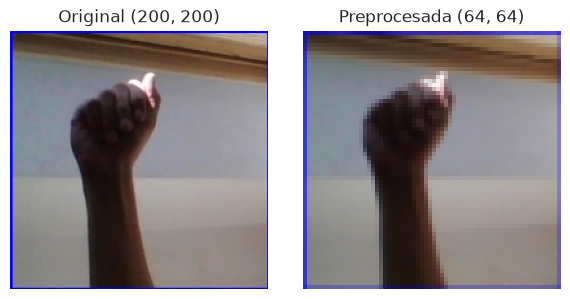

In [11]:
IMG_SIZE = 64
RESAMPLE_METHOD = Image.Resampling.BILINEAR

def load_and_preprocess(filepath, size=IMG_SIZE, preserve_aspect_ratio=False):
    with Image.open(filepath) as source:
        img = source.convert("RGB")
        if preserve_aspect_ratio:
            img = ImageOps.pad(
                img,
                (size, size),
                method=RESAMPLE_METHOD,
                color=(0, 0, 0),
                centering=(0.5, 0.5),
            )
        else:
            img = img.resize((size, size), resample=RESAMPLE_METHOD)
        return np.asarray(img, dtype=np.float32) / 255.0

# Ejemplo: antes / después de preprocesar una imagen cuadrada del conjunto base
example_path = train_sub.filepath.iloc[0]
original = Image.open(example_path)
processed = load_and_preprocess(example_path)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(original)
axes[0].set_title(f"Original {original.size}")
axes[0].axis("off")
axes[1].imshow(processed)
axes[1].set_title(f"Preprocesada {processed.shape[:2]}")
axes[1].axis("off")
plt.tight_layout()
plt.show()


### 3.2 Construcción de los arreglos de entrenamiento

Cargamos las imágenes preprocesadas a arreglos de NumPy y codificamos las etiquetas. El `LabelEncoder` se ajusta solo con train, para evitar fuga de información.

In [12]:
encoder = LabelEncoder()
encoder.fit(train_sub.label)

def build_arrays(data):
    X = np.stack([load_and_preprocess(p) for p in data.filepath])
    y = to_categorical(encoder.transform(data.label), num_classes=len(CLASSES))
    return X, y

X_train, y_train = build_arrays(train_sub)
X_val, y_val = build_arrays(val_sub)

print(X_train.shape, X_val.shape)

(12180, 64, 64, 3) (2610, 64, 64, 3)


## Ejercicio 4 — Modelos de Deep Learning (CNN)

Se comparan dos arquitecturas CNN requeridas. CNN 1 funciona como línea base compacta; CNN 2 varía de forma explícita la profundidad, la cantidad de filtros, la capacidad de la capa densa y la regularización. La tabla de configuración hace visibles estas decisiones. El modelo CNN final se selecciona únicamente por validación después de comparar también las variantes aumentadas del ejercicio 7; Random Forest y la red densa se mantienen como líneas base de familias distintas.


In [13]:
def plot_history(history, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="validación")
    plt.title(title)
    plt.xlabel("Época")
    plt.ylabel("Pérdida")
    plt.legend()
    plt.tight_layout()
    plt.show()

def evaluate_model(model, X, y, name, split_name):
    loss, acc = model.evaluate(X, y, verbose=0)
    print(f"{name} - accuracy en {split_name}: {acc:.3f}")
    return loss, acc

def make_early_stop():
    return callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    )


### 4.1 CNN 1 — arquitectura simple

In [14]:
def build_cnn_1(augmentation=None):
    model_layers = [layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))]
    if augmentation is not None:
        model_layers.append(augmentation)
    model_layers.extend([
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D(2, 2),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(len(CLASSES), activation="softmax"),
    ])
    model = models.Sequential(model_layers)
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

cnn_1 = build_cnn_1()
cnn_1.summary()


E0000 00:00:1786338826.898209 1546721 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,628,893 (6.21 MB)

 Trainable params: 1,628,893 (6.21 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


381/381 - 13s - 35ms/step - accuracy: 0.3618 - loss: 2.2180 - val_accuracy: 0.5824 - val_loss: 1.3020


Epoch 2/30


381/381 - 12s - 32ms/step - accuracy: 0.7443 - loss: 0.8168 - val_accuracy: 0.7920 - val_loss: 0.6839


Epoch 3/30


381/381 - 12s - 32ms/step - accuracy: 0.8798 - loss: 0.3930 - val_accuracy: 0.8682 - val_loss: 0.4383


... (24 outputs left out)

Epoch 16/30


381/381 - 10s - 26ms/step - accuracy: 0.9942 - loss: 0.0204 - val_accuracy: 0.9211 - val_loss: 0.3804


Epoch 17/30


381/381 - 10s - 25ms/step - accuracy: 0.9882 - loss: 0.0369 - val_accuracy: 0.9307 - val_loss: 0.3372


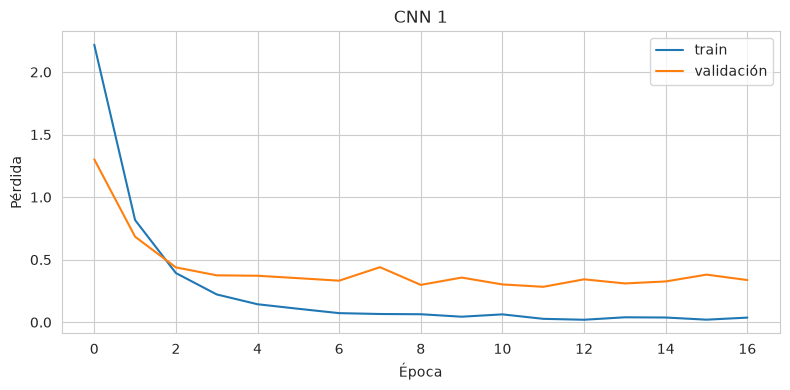

CNN 1 - accuracy en validación: 0.933


In [15]:
history_cnn_1 = cnn_1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[make_early_stop()],
    verbose=2,
)

plot_history(history_cnn_1, "CNN 1")
val_loss_cnn_1, val_acc_cnn_1 = evaluate_model(cnn_1, X_val, y_val, "CNN 1", "validación")


La CNN 1 converge rápido, pero su pérdida de entrenamiento se aproxima a cero mientras la de validación deja de disminuir y oscila. Esa separación evidencia sobreajuste y concuerda con su accuracy de validación de 0.933333; se mantiene como línea base, no como modelo final.

### 4.2 CNN 2 — arquitectura más profunda, con dropout

In [16]:
def build_cnn_2(augmentation=None):
    model_layers = [layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))]
    if augmentation is not None:
        model_layers.append(augmentation)
    model_layers.extend([
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D(2, 2),
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(len(CLASSES), activation="softmax"),
    ])
    model = models.Sequential(model_layers)
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

cnn_2 = build_cnn_2()
cnn_2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │         7,453 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,280,605 (4.89 MB)

 Trainable params: 1,280,605 (4.89 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
cnn_architecture_comparison = pd.DataFrame([
    {
        "modelo": "CNN 1",
        "bloques_convolucionales": 2,
        "filtros": "32 → 64",
        "unidades_densas": 128,
        "dropout": 0.0,
        "learning_rate": "Adam por defecto",
        "batch_size": 32,
        "parámetros": cnn_1.count_params(),
    },
    {
        "modelo": "CNN 2",
        "bloques_convolucionales": 3,
        "filtros": "32 → 64 → 128",
        "unidades_densas": 256,
        "dropout": 0.5,
        "learning_rate": "Adam por defecto",
        "batch_size": 32,
        "parámetros": cnn_2.count_params(),
    },
])
display(cnn_architecture_comparison)

,modelo,bloques_convolucionales,filtros,unidades_densas,dropout,learning_rate,batch_size,parámetros
0,CNN 1,2,32 → 64,128,0.0,Adam por defecto,32,1628893
1,CNN 2,3,32 → 64 → 128,256,0.5,Adam por defecto,32,1280605


Epoch 1/30


381/381 - 13s - 33ms/step - accuracy: 0.2173 - loss: 2.6814 - val_accuracy: 0.5441 - val_loss: 1.5383


Epoch 2/30


381/381 - 12s - 32ms/step - accuracy: 0.5965 - loss: 1.2364 - val_accuracy: 0.7831 - val_loss: 0.7337


Epoch 3/30


381/381 - 12s - 33ms/step - accuracy: 0.7579 - loss: 0.7203 - val_accuracy: 0.8881 - val_loss: 0.3902


... (50 outputs left out)

Epoch 29/30


381/381 - 13s - 33ms/step - accuracy: 0.9859 - loss: 0.0469 - val_accuracy: 0.9820 - val_loss: 0.0756


Epoch 30/30


381/381 - 12s - 32ms/step - accuracy: 0.9867 - loss: 0.0428 - val_accuracy: 0.9820 - val_loss: 0.0819


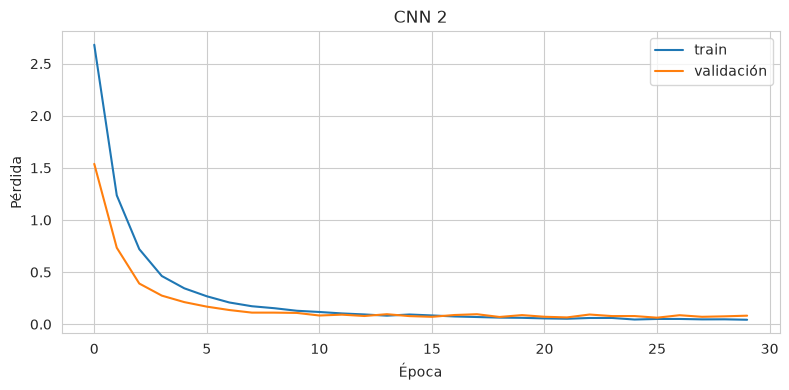

CNN 2 - accuracy en validación: 0.987


In [18]:
history_cnn_2 = cnn_2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[make_early_stop()],
    verbose=2,
)

plot_history(history_cnn_2, "CNN 2")
val_loss_cnn_2, val_acc_cnn_2 = evaluate_model(cnn_2, X_val, y_val, "CNN 2", "validación")


En la CNN 2, las pérdidas de entrenamiento y validación descienden de forma sostenida y permanecen próximas en valores bajos, sin la separación marcada de la CNN 1. Esta señal de mejor generalización, junto con la accuracy de validación de 0.986973 frente a 0.933333, determina que CNN 2 sea la mejor arquitectura base. El conjunto de prueba permanece reservado para una única evaluación final después de comparar las variantes con aumento.


In [19]:
best_base_cnn = cnn_2 if val_acc_cnn_2 > val_acc_cnn_1 else cnn_1
best_base_cnn_name = "CNN 2" if val_acc_cnn_2 > val_acc_cnn_1 else "CNN 1"
best_base_val_acc = max(val_acc_cnn_1, val_acc_cnn_2)
print(f"Mejor CNN base según validación: {best_base_cnn_name}")


Mejor CNN base según validación: CNN 2


La salida confirma que `best_base_cnn_name` es CNN 2. La selección usa únicamente validación y combina el mejor resultado medido con curvas que muestran una brecha de generalización menor; el test no interviene en esta decisión.


### 4.3 Matriz de confusión de la mejor CNN base en validación


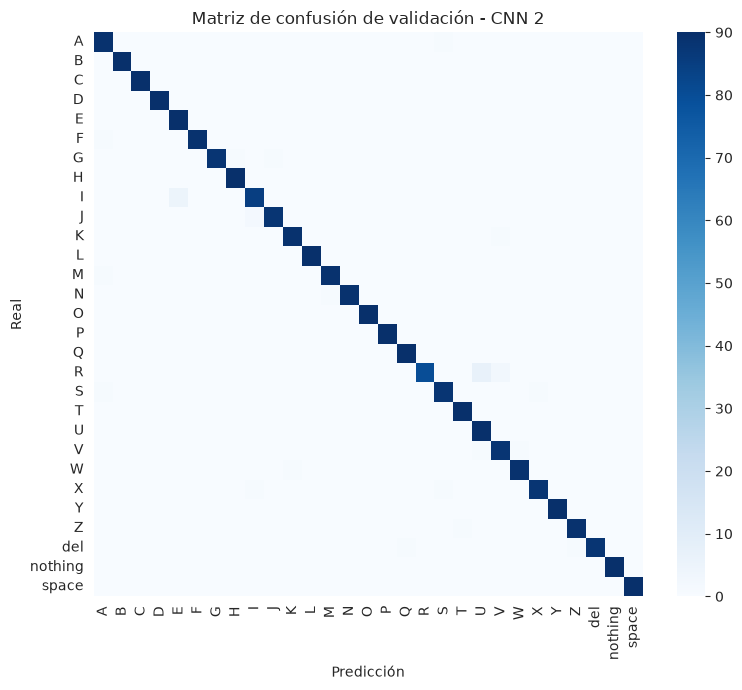

In [20]:
y_pred_val = best_base_cnn.predict(X_val, verbose=0).argmax(axis=1)
y_true_val = y_val.argmax(axis=1)

cm = confusion_matrix(y_true_val, y_pred_val)
plt.figure(figsize=(8, 7))
sns.heatmap(cm, xticklabels=encoder.classes_, yticklabels=encoder.classes_, cmap="Blues")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(f"Matriz de confusión de validación - {best_base_cnn_name}")
plt.tight_layout()
plt.show()


La matriz de CNN 2 está fuertemente concentrada en la diagonal y presenta errores aislados fuera de ella, sin bloques amplios de confusión entre grupos de clases. Como la figura almacenada no anota conteos por celda, no se atribuyen cantidades exactas a pares de clases. El patrón respalda la accuracy de validación de 0.986973 y la selección de CNN 2 dentro del conjunto controlado, pero no sustituye la evaluación con fotografías propias bajo cambio de dominio.


## Ejercicio 5 — Red neuronal simple (fully-connected)

Se entrenan tres configuraciones densas reproducibles para variar capacidad y regularización: una capa de 128 unidades; dos capas de 256→128; y 256→128 con dropout de 0.30. Todas usan el mismo split, batch y criterio de parada. La selección de la mejor variante usa únicamente validación.


In [21]:
def build_dense_nn(hidden_units, dropout=0.0, learning_rate=1e-3):
    model_layers = [
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Flatten(),
    ]
    for units in hidden_units:
        model_layers.append(layers.Dense(units, activation="relu"))
        if dropout:
            model_layers.append(layers.Dropout(dropout))
    model_layers.append(layers.Dense(len(CLASSES), activation="softmax"))

    model = models.Sequential(model_layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

dense_configurations = [
    {"modelo": "Densa 128", "hidden_units": (128,), "dropout": 0.0, "learning_rate": 1e-3},
    {"modelo": "Densa 256→128", "hidden_units": (256, 128), "dropout": 0.0, "learning_rate": 1e-3},
    {"modelo": "Densa 256→128 + dropout", "hidden_units": (256, 128), "dropout": 0.30, "learning_rate": 1e-3},
]

display(pd.DataFrame(dense_configurations))


,modelo,hidden_units,dropout,learning_rate
0,Densa 128,"(128,)",0.0,0.001
1,Densa 256→128,"(256, 128)",0.0,0.001
2,Densa 256→128 + dropout,"(256, 128)",0.3,0.001


Epoch 1/20


381/381 - 2s - 6ms/step - accuracy: 0.0312 - loss: 3.5268 - val_accuracy: 0.0345 - val_loss: 3.3668


Epoch 2/20


381/381 - 2s - 5ms/step - accuracy: 0.0302 - loss: 3.3676 - val_accuracy: 0.0341 - val_loss: 3.3673


Epoch 3/20


381/381 - 2s - 6ms/step - accuracy: 0.0300 - loss: 3.3677 - val_accuracy: 0.0341 - val_loss: 3.3673


... (3 outputs left out)

381/381 - 2s - 6ms/step - accuracy: 0.0278 - loss: 3.3677 - val_accuracy: 0.0341 - val_loss: 3.3673


Epoch 6/20


381/381 - 2s - 6ms/step - accuracy: 0.0282 - loss: 3.3678 - val_accuracy: 0.0341 - val_loss: 3.3673


Densa 128 - accuracy en validación: 0.034


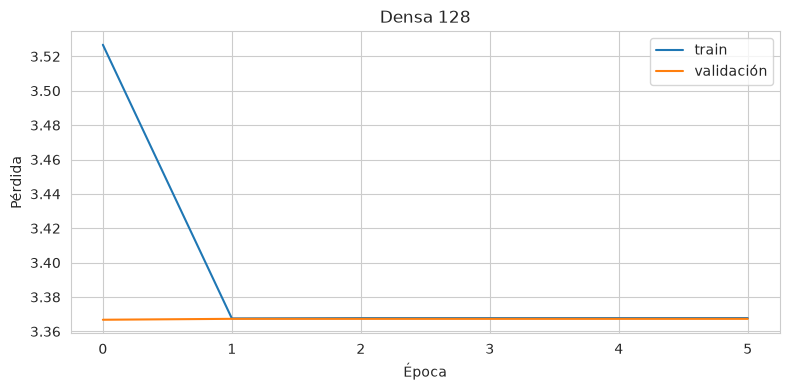

Epoch 1/20


381/381 - 5s - 13ms/step - accuracy: 0.0851 - loss: 3.4239 - val_accuracy: 0.1207 - val_loss: 3.1933


Epoch 2/20


381/381 - 5s - 13ms/step - accuracy: 0.1756 - loss: 2.8294 - val_accuracy: 0.2027 - val_loss: 2.6724


Epoch 3/20


381/381 - 4s - 11ms/step - accuracy: 0.2563 - loss: 2.4317 - val_accuracy: 0.3100 - val_loss: 2.3022


... (31 outputs left out)

381/381 - 4s - 11ms/step - accuracy: 0.6890 - loss: 0.8745 - val_accuracy: 0.6307 - val_loss: 1.0896


Epoch 20/20


381/381 - 4s - 10ms/step - accuracy: 0.7037 - loss: 0.8367 - val_accuracy: 0.6628 - val_loss: 1.0019


Densa 256→128 - accuracy en validación: 0.663


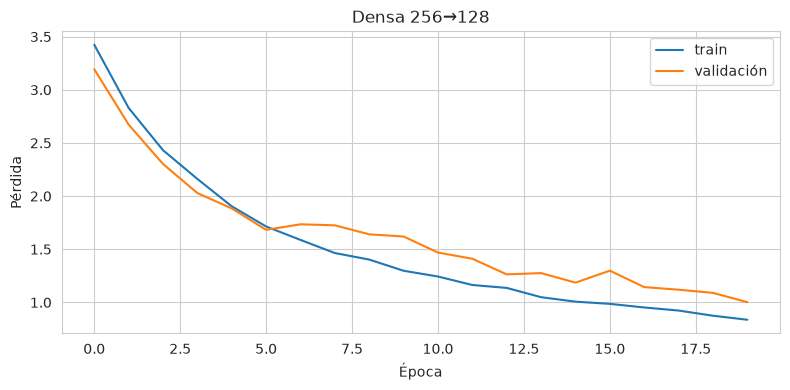

Epoch 1/20


381/381 - 4s - 12ms/step - accuracy: 0.0308 - loss: 3.4794 - val_accuracy: 0.0345 - val_loss: 3.3673


Epoch 2/20


381/381 - 4s - 11ms/step - accuracy: 0.0296 - loss: 3.3709 - val_accuracy: 0.0345 - val_loss: 3.3673


Epoch 3/20


381/381 - 5s - 12ms/step - accuracy: 0.0293 - loss: 3.3678 - val_accuracy: 0.0345 - val_loss: 3.3673


... (7 outputs left out)

381/381 - 4s - 10ms/step - accuracy: 0.0277 - loss: 3.3678 - val_accuracy: 0.0345 - val_loss: 3.3673


Epoch 8/20


381/381 - 4s - 11ms/step - accuracy: 0.0273 - loss: 3.3678 - val_accuracy: 0.0345 - val_loss: 3.3673


Densa 256→128 + dropout - accuracy en validación: 0.034


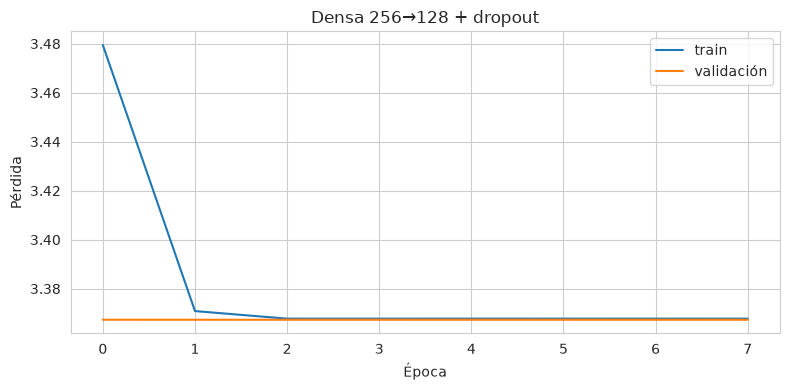

,modelo,accuracy_validacion,loss_validacion,parámetros
0,Densa 256→128,0.662835,1.001914,3182621
1,Densa 128,0.034483,3.366783,1576733
2,Densa 256→128 + dropout,0.034483,3.367307,3182621


Mejor variante densa según validación: Densa 256→128


In [22]:
dense_models = {}
dense_histories = {}
dense_records = []

for config in dense_configurations:
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    model = build_dense_nn(
        hidden_units=config["hidden_units"],
        dropout=config["dropout"],
        learning_rate=config["learning_rate"],
    )
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=32,
        callbacks=[make_early_stop()],
        verbose=2,
    )
    val_loss, val_acc = evaluate_model(model, X_val, y_val, config["modelo"], "validación")
    dense_models[config["modelo"]] = model
    dense_histories[config["modelo"]] = history
    dense_records.append({
        "modelo": config["modelo"],
        "accuracy_validacion": val_acc,
        "loss_validacion": val_loss,
        "parámetros": model.count_params(),
    })
    plot_history(history, config["modelo"])

dense_results = pd.DataFrame(dense_records).sort_values(
    ["accuracy_validacion", "loss_validacion"],
    ascending=[False, True],
).reset_index(drop=True)
display(dense_results)

best_dense_name = dense_results.loc[0, "modelo"]
nn_simple = dense_models[best_dense_name]
history_nn = dense_histories[best_dense_name]
val_acc_nn = dense_results.loc[0, "accuracy_validacion"]
val_loss_nn = dense_results.loc[0, "loss_validacion"]
print(f"Mejor variante densa según validación: {best_dense_name}")


Las curvas de `Densa 128` y `Densa 256→128 + dropout` se estabilizan casi de inmediato alrededor de la pérdida 3.37 y ambas alcanzan accuracy de validación 0.034483, señal de que no aprendieron una separación útil. En cambio, `Densa 256→128` reduce de forma sostenida las pérdidas durante 20 épocas; la curva de entrenamiento queda por debajo de validación, pero ambas mantienen una tendencia descendente sin una reversión sostenida. Por ello se selecciona esta variante densa con accuracy 0.662835 y pérdida 1.001914, aunque queda claramente por debajo de las CNN y de Random Forest para la decisión final.


## Ejercicio 6 — Modelo con otro algoritmo

Elegimos Random Forest como algoritmo alternativo: no necesita escalado de datos, maneja bien datos de alta dimensión como los píxeles aplanados, y sirve como referencia rápida frente a los modelos de deep learning.

In [23]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)

y_train_labels = y_train.argmax(axis=1)
y_val_labels = y_val.argmax(axis=1)


In [24]:
rf_records = []

for n_trees in [100, 300, 500]:
    rf = RandomForestClassifier(n_estimators=n_trees, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_flat, y_train_labels)
    val_acc = rf.score(X_val_flat, y_val_labels)
    rf_records.append({"n_estimators": n_trees, "accuracy_validacion": val_acc})

rf_results = pd.DataFrame(rf_records).sort_values(
    ["accuracy_validacion", "n_estimators"],
    ascending=[False, True],
).reset_index(drop=True)
display(rf_results)


,n_estimators,accuracy_validacion
0,300,0.968966
1,500,0.968966
2,100,0.965134


Se comparan 100, 300 y 500 árboles porque aumentar `n_estimators` suele estabilizar el ensamble, pero también incrementa tiempo y memoria. Se selecciona por validación y, si hay empate, se prefiere el bosque con menos árboles para conservar la alternativa más eficiente. El conjunto de prueba no interviene.


In [25]:
best_n_trees = int(rf_results.loc[0, "n_estimators"])
rf_final = RandomForestClassifier(
    n_estimators=best_n_trees,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_final.fit(X_train_flat, y_train_labels)
val_acc_rf = rf_final.score(X_val_flat, y_val_labels)
print(f"Random Forest seleccionado: {best_n_trees} árboles")
print(f"Random Forest - accuracy en validación: {val_acc_rf:.3f}")


Random Forest seleccionado: 300 árboles
Random Forest - accuracy en validación: 0.969


### Comparación de todos los modelos

,modelo,accuracy_validacion
1,CNN 2,0.986973
3,Random Forest (300),0.968966
0,CNN 1,0.933333
2,Densa 256→128,0.662835


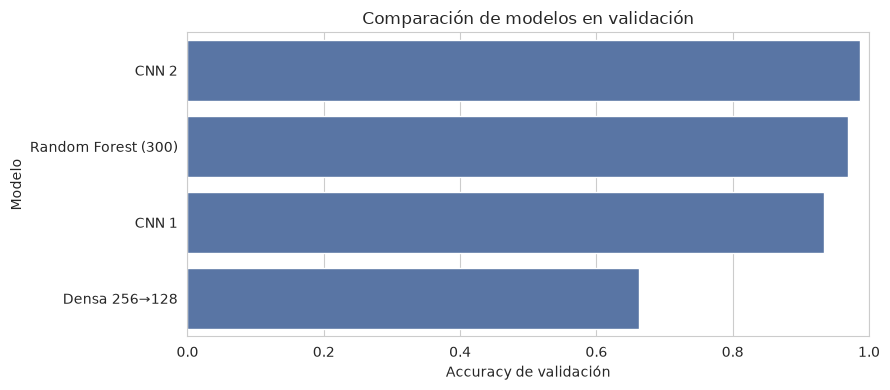

In [26]:
resultados_validacion = pd.DataFrame({
    "modelo": ["CNN 1", "CNN 2", best_dense_name, f"Random Forest ({best_n_trees})"],
    "accuracy_validacion": [val_acc_cnn_1, val_acc_cnn_2, val_acc_nn, val_acc_rf],
}).sort_values("accuracy_validacion", ascending=False)

display(resultados_validacion)

plt.figure(figsize=(9, 4))
sns.barplot(data=resultados_validacion, x="accuracy_validacion", y="modelo", color="#4C72B0")
plt.xlim(0, 1)
plt.xlabel("Accuracy de validación")
plt.ylabel("Modelo")
plt.title("Comparación de modelos en validación")
plt.tight_layout()
plt.show()


La comparación de validación ordena CNN 2 (0.986973), Random Forest con 300 árboles (0.968966), CNN 1 (0.933333) y la red densa 256→128 (0.662835). La figura muestra que CNN 2 lidera antes del aumento; la selección definitiva se completa al comparar sus variantes aumentadas, siempre sin usar el resultado de prueba para ordenar modelos o ajustar hiperparámetros.


## Ejercicio 7 — Aumento de datos

Se reentrenan **CNN 1 y CNN 2** con la misma familia y magnitud de transformaciones semánticamente seguras: rotación pequeña, zoom moderado, traslación y contraste. Estas variaciones representan cambios plausibles de cámara, encuadre e iluminación sin modificar deliberadamente la configuración de la mano.

No se usan reflejos horizontales ni verticales. Un reflejo horizontal cambia la lateralidad y la orientación de la palma; uno vertical invierte por completo la postura. En ASL, orientación, dirección y relación entre dedos forman parte del significado, por lo que un flip puede convertir una muestra en una seña inválida o distinta. Las cuatro CNN se comparan solo en validación y el test reservado se consulta una única vez después de seleccionar la CNN final.


In [27]:
def build_data_augmentation(name):
    return models.Sequential([
        layers.RandomRotation(0.04, fill_mode="nearest", seed=RANDOM_STATE),
        layers.RandomZoom(0.08, fill_mode="nearest", seed=RANDOM_STATE + 1),
        layers.RandomTranslation(0.08, 0.08, fill_mode="nearest", seed=RANDOM_STATE + 2),
        layers.RandomContrast(0.10, seed=RANDOM_STATE + 3),
    ], name=name)

tf.keras.utils.set_random_seed(RANDOM_STATE)
cnn_1_augmented = build_cnn_1(build_data_augmentation("augmentation_cnn_1"))
tf.keras.utils.set_random_seed(RANDOM_STATE)
cnn_2_augmented = build_cnn_2(build_data_augmentation("augmentation_cnn_2"))

augmentation_comparison = pd.DataFrame([
    {"transformación": "Rotación", "magnitud": "±4% de vuelta"},
    {"transformación": "Zoom", "magnitud": "±8%"},
    {"transformación": "Traslación", "magnitud": "±8% horizontal/vertical"},
    {"transformación": "Contraste", "magnitud": "±10%"},
    {"transformación": "Flips", "magnitud": "No aplicados"},
])
display(augmentation_comparison)


,transformación,magnitud
0,Rotación,±4% de vuelta
1,Zoom,±8%
2,Traslación,±8% horizontal/vertical
3,Contraste,±10%
4,Flips,No aplicados


Epoch 1/30


381/381 - 11s - 28ms/step - accuracy: 0.2344 - loss: 2.6643 - val_accuracy: 0.4682 - val_loss: 1.7680


Epoch 2/30


381/381 - 10s - 26ms/step - accuracy: 0.5042 - loss: 1.6033 - val_accuracy: 0.6395 - val_loss: 1.0946


Epoch 3/30


381/381 - 10s - 26ms/step - accuracy: 0.6294 - loss: 1.1744 - val_accuracy: 0.7441 - val_loss: 0.8007


... (50 outputs left out)

Epoch 29/30


381/381 - 10s - 26ms/step - accuracy: 0.9531 - loss: 0.1356 - val_accuracy: 0.9548 - val_loss: 0.1527


Epoch 30/30


381/381 - 10s - 25ms/step - accuracy: 0.9560 - loss: 0.1308 - val_accuracy: 0.9705 - val_loss: 0.0856


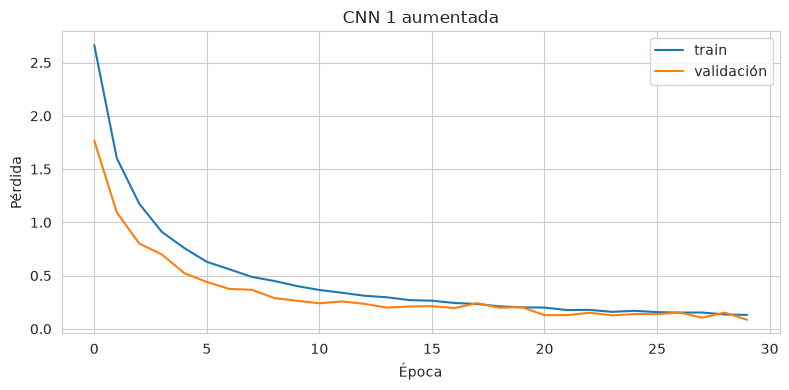

CNN 1 aumentada - accuracy en validación: 0.970


Epoch 1/30


381/381 - 13s - 33ms/step - accuracy: 0.1787 - loss: 2.8414 - val_accuracy: 0.5126 - val_loss: 1.7028


Epoch 2/30


381/381 - 11s - 30ms/step - accuracy: 0.4870 - loss: 1.6419 - val_accuracy: 0.7479 - val_loss: 0.8759


Epoch 3/30


... (39 outputs left out)

Epoch 23/30


381/381 - 13s - 35ms/step - accuracy: 0.9427 - loss: 0.1706 - val_accuracy: 0.9812 - val_loss: 0.0678


Epoch 24/30


381/381 - 14s - 37ms/step - accuracy: 0.9410 - loss: 0.1741 - val_accuracy: 0.9805 - val_loss: 0.0625


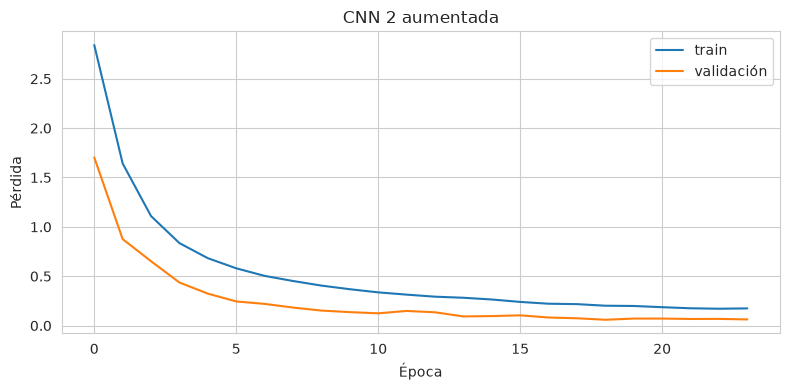

CNN 2 aumentada - accuracy en validación: 0.980


,modelo,accuracy_validacion
0,CNN 2 base,0.986973
1,CNN 2 aumentada,0.980460
2,CNN 1 aumentada,0.970498
3,CNN 1 base,0.933333


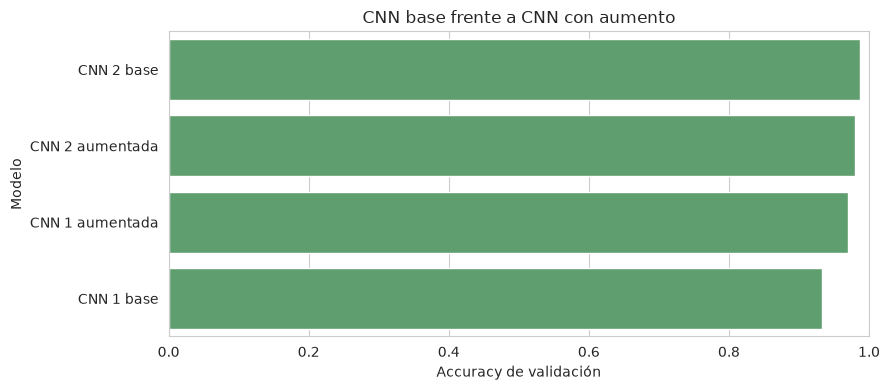

CNN final seleccionada exclusivamente con validación: CNN 2


CNN 2 - accuracy en test final: 0.987


In [28]:
augmented_experiments = [
    ("CNN 1 aumentada", cnn_1_augmented),
    ("CNN 2 aumentada", cnn_2_augmented),
]
augmented_records = []

for model_name, model in augmented_experiments:
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=32,
        callbacks=[make_early_stop()],
        verbose=2,
    )
    plot_history(history, model_name)
    val_loss, val_acc = evaluate_model(model, X_val, y_val, model_name, "validación")
    augmented_records.append({
        "modelo": model_name,
        "accuracy_validacion": val_acc,
        "loss_validacion": val_loss,
    })

augmented_results = pd.DataFrame(augmented_records)
comparacion_aumento = pd.DataFrame([
    {"modelo": "CNN 1 base", "accuracy_validacion": val_acc_cnn_1},
    {"modelo": "CNN 1 aumentada", "accuracy_validacion": augmented_results.loc[0, "accuracy_validacion"]},
    {"modelo": "CNN 2 base", "accuracy_validacion": val_acc_cnn_2},
    {"modelo": "CNN 2 aumentada", "accuracy_validacion": augmented_results.loc[1, "accuracy_validacion"]},
]).sort_values("accuracy_validacion", ascending=False).reset_index(drop=True)
display(comparacion_aumento)

plt.figure(figsize=(9, 4))
sns.barplot(data=comparacion_aumento, x="accuracy_validacion", y="modelo", color="#55A868")
plt.xlim(0, 1)
plt.xlabel("Accuracy de validación")
plt.ylabel("Modelo")
plt.title("CNN base frente a CNN con aumento")
plt.tight_layout()
plt.show()

cnn_candidates = [
    ("CNN 1", cnn_1, val_acc_cnn_1),
    ("CNN 2", cnn_2, val_acc_cnn_2),
    ("CNN 1 aumentada", cnn_1_augmented, augmented_results.loc[0, "accuracy_validacion"]),
    ("CNN 2 aumentada", cnn_2_augmented, augmented_results.loc[1, "accuracy_validacion"]),
]
final_cnn_name, final_cnn, final_cnn_val_acc = max(cnn_candidates, key=lambda item: item[2])
print(f"CNN final seleccionada exclusivamente con validación: {final_cnn_name}")

# El conjunto reservado se carga y consulta solo después de cerrar toda selección.
X_test, y_test = build_arrays(test_sub)
final_test_loss, final_test_acc = evaluate_model(
    final_cnn,
    X_test,
    y_test,
    final_cnn_name,
    "test final",
)


Las curvas aumentadas descienden de forma estable y mantienen próximas las pérdidas de entrenamiento y validación. En CNN 1, este comportamiento reduce la separación observada en la curva base y mejora la accuracy de validación de 0.933333 a 0.970498. En CNN 2, la variante aumentada alcanza 0.980460, por debajo de 0.986973 de la base; por ello el aumento no mejora esta arquitectura y CNN 2 base permanece seleccionada. `final_test_acc` se genera una sola vez después de fijar `final_cnn` y no retroalimenta la decisión.


## Ejercicio 8 — Evaluación con fotografías propias

La evaluación privada usa 15 fotografías únicas de exactamente tres participantes reales identificados solo mediante seudónimos: `orion` (Orión), `nebula` (Nébula) y `lactea` (Láctea). Cada participante debe aportar por lo menos cinco letras distintas. El notebook valida los participantes, la cobertura y los hashes antes de predecir, y reporta dinámicamente cada imagen, el total general y los aciertos, cantidad y accuracy por participante.

Los archivos se almacenan localmente en `data/own_photos/<participante>/<ETIQUETA>_<número>.<ext>` y no se incluyen en Git. Se admiten `.jpg`, `.jpeg` y `.png`; la etiqueta es el texto anterior al primer guion bajo. `ASL_OWN_PHOTOS_DIR` permite configurar otra ubicación.

Como estas capturas son rectangulares, se conserva su relación de aspecto con relleno cuadrado centrado antes de producir 64×64. Esto evita deformar la mano, aunque las bandas de relleno y la escala efectiva pueden seguir diferenciándose del dominio de entrenamiento. Los seudónimos no se usan para inferir ni autenticar identidades.


,participante,cantidad_imagenes,cantidad_letras_distintas,letras
0,Orión,5,5,"C, F, I, L, S"
1,Nébula,5,5,"Q, R, U, V, X"
2,Láctea,5,5,"A, B, D, F, L"


,participante,archivo,etiqueta_real,prediccion,confianza,correcta
0,Orión,C_01.jpeg,C,space,0.999999,False
1,Orión,F_01.jpeg,F,N,0.539014,False
2,Orión,I_01.jpeg,I,I,0.996874,True
3,Orión,L_01.jpeg,L,Y,0.988919,False
4,Orión,S_01.jpeg,S,Y,0.645137,False
5,Nébula,Q_01.jpeg,Q,Q,1.000000,True
6,Nébula,R_01.jpeg,R,space,0.835957,False
7,Nébula,U_01.jpeg,U,B,0.857579,False
8,Nébula,V_01.jpeg,V,K,0.986864,False
9,Nébula,X_01.jpeg,X,space,0.811833,False


,participante,aciertos,cantidad,accuracy
0,Total,2,15,0.133333


,participante,aciertos,cantidad,accuracy
0,Láctea,0,5,0.0
1,Nébula,1,5,0.2
2,Orión,1,5,0.2


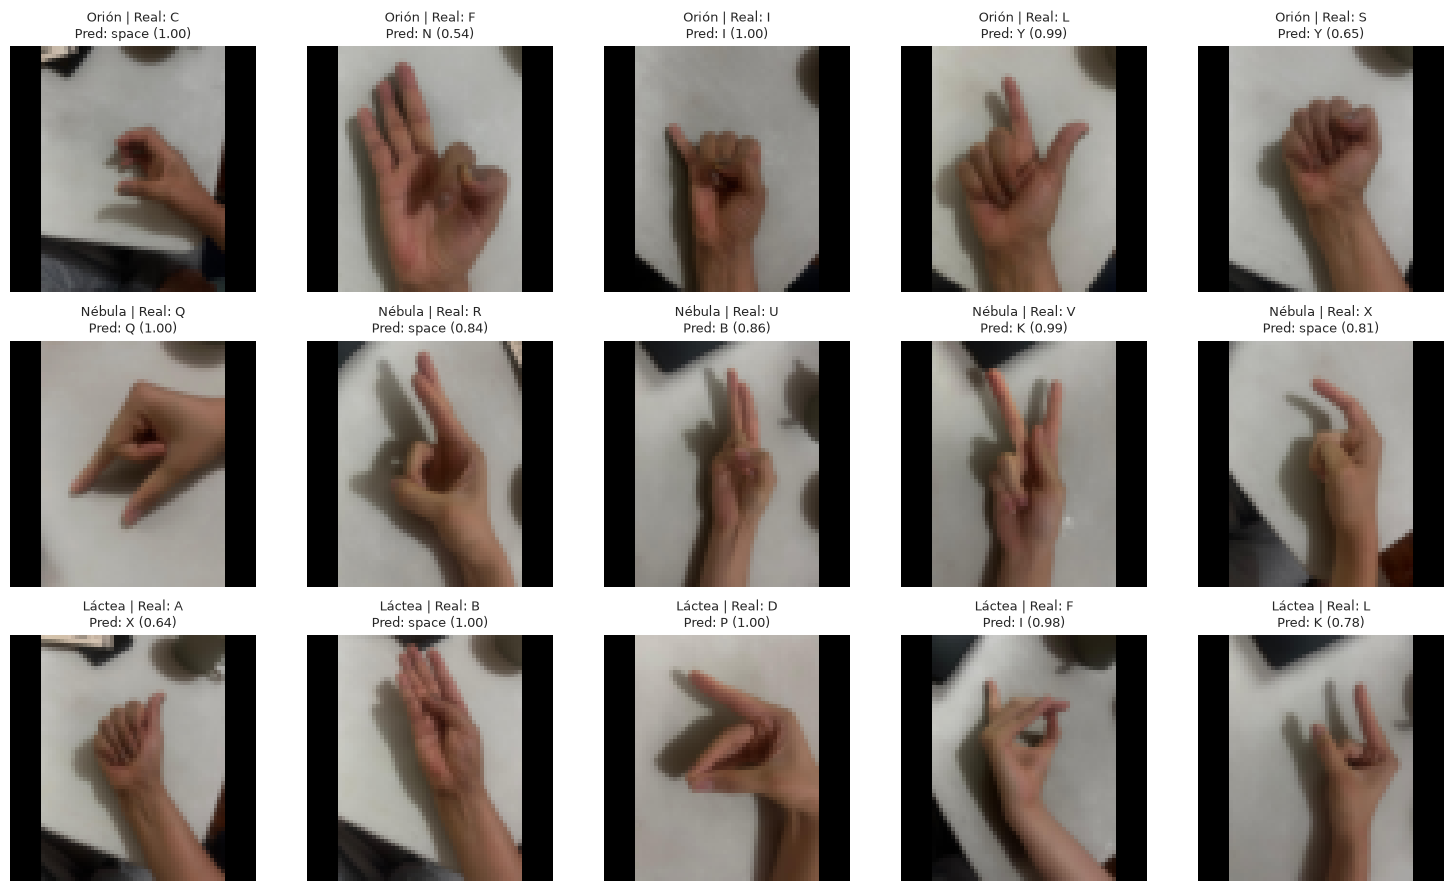

In [29]:
configured_photos_dir = os.getenv("ASL_OWN_PHOTOS_DIR")
photo_dir_candidates = (
    [Path(configured_photos_dir).expanduser()]
    if configured_photos_dir
    else [Path("data/own_photos"), Path("../data/own_photos")]
)
OWN_PHOTOS_DIR = next(
    (candidate.resolve() for candidate in photo_dir_candidates if candidate.is_dir()),
    None,
)
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png"}
SUBJECT_DISPLAY_NAMES = {
    "orion": "Orión",
    "nebula": "Nébula",
    "lactea": "Láctea",
}
MIN_DISTINCT_LETTERS = 5
EXPECTED_UNIQUE_PHOTO_HASHES = 15

if OWN_PHOTOS_DIR is None:
    searched_paths = ", ".join(str(candidate.resolve()) for candidate in photo_dir_candidates)
    raise FileNotFoundError(
        f"No se encontró el directorio privado de fotografías. Rutas revisadas: {searched_paths}. "
        "Use data/own_photos/<participante>/<ETIQUETA>_<número>.<ext> o defina "
        "ASL_OWN_PHOTOS_DIR."
    )

expected_subject_slugs = set(SUBJECT_DISPLAY_NAMES)
actual_subject_slugs = {path.name for path in OWN_PHOTOS_DIR.iterdir() if path.is_dir()}
if actual_subject_slugs != expected_subject_slugs:
    missing = sorted(expected_subject_slugs - actual_subject_slugs)
    unexpected = sorted(actual_subject_slugs - expected_subject_slugs)
    raise ValueError(
        "La evaluación requiere exactamente tres participantes: "
        f"{sorted(expected_subject_slugs)}. Faltantes: {missing}; inesperados: {unexpected}"
    )

photo_records = []
coverage_records = []
for subject_slug, display_name in SUBJECT_DISPLAY_NAMES.items():
    subject_dir = OWN_PHOTOS_DIR / subject_slug
    if not subject_dir.is_dir():
        raise FileNotFoundError(f"Falta la carpeta requerida para {display_name}: {subject_dir}")

    subject_paths = sorted(
        path for path in subject_dir.iterdir()
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )
    labels = [path.stem.split("_", 1)[0].upper() for path in subject_paths]
    invalid_labels = sorted(set(labels) - set(encoder.classes_))
    if invalid_labels:
        raise ValueError(f"{display_name} contiene etiquetas desconocidas: {invalid_labels}")

    distinct_labels = sorted(set(labels))
    coverage_records.append({
        "participante": display_name,
        "cantidad_imagenes": len(subject_paths),
        "cantidad_letras_distintas": len(distinct_labels),
        "letras": ", ".join(distinct_labels),
    })
    photo_records.extend(
        {"participante": display_name, "path": path, "etiqueta_real": label}
        for path, label in zip(subject_paths, labels)
    )

subject_coverage = pd.DataFrame(coverage_records)
display(subject_coverage)
if (subject_coverage["cantidad_letras_distintas"] < MIN_DISTINCT_LETTERS).any():
    insufficient = subject_coverage.loc[
        subject_coverage["cantidad_letras_distintas"] < MIN_DISTINCT_LETTERS,
        "participante",
    ].tolist()
    raise ValueError(
        f"Cada participante requiere al menos {MIN_DISTINCT_LETTERS} letras distintas. "
        f"Cobertura insuficiente: {insufficient}"
    )

photos_by_hash = {}
for record in photo_records:
    photo_hash = hashlib.sha256(record["path"].read_bytes()).hexdigest()
    photos_by_hash.setdefault(photo_hash, []).append(
        f'{record["participante"]}/{record["path"].name}'
    )
duplicate_hashes = {
    photo_hash: paths for photo_hash, paths in photos_by_hash.items() if len(paths) > 1
}
if duplicate_hashes:
    duplicate_details = "; ".join(
        f"{photo_hash}: {', '.join(paths)}"
        for photo_hash, paths in sorted(duplicate_hashes.items())
    )
    raise ValueError(
        "Se detectaron fotografías duplicadas por contenido. Elimine las copias para no "
        f"contar una misma foto en más de un participante: {duplicate_details}"
    )
if len(photos_by_hash) != EXPECTED_UNIQUE_PHOTO_HASHES:
    raise ValueError(
        f"La evaluación requiere exactamente {EXPECTED_UNIQUE_PHOTO_HASHES} hashes de "
        f"fotografía únicos; se encontraron {len(photos_by_hash)}."
    )

photo_paths = [record["path"] for record in photo_records]
own_images = np.stack([
    load_and_preprocess(path, preserve_aspect_ratio=True)
    for path in photo_paths
])
probabilities = final_cnn.predict(own_images, verbose=0)
predicted_labels = encoder.inverse_transform(probabilities.argmax(axis=1))

own_results = pd.DataFrame({
    "participante": [record["participante"] for record in photo_records],
    "archivo": [record["path"].name for record in photo_records],
    "etiqueta_real": [record["etiqueta_real"] for record in photo_records],
    "prediccion": predicted_labels,
    "confianza": probabilities.max(axis=1),
})
own_results["correcta"] = own_results["etiqueta_real"] == own_results["prediccion"]

own_overall_results = pd.DataFrame([{
    "participante": "Total",
    "aciertos": int(own_results["correcta"].sum()),
    "cantidad": len(own_results),
    "accuracy": own_results["correcta"].mean(),
}])
own_subject_results = (
    own_results.groupby("participante", as_index=False)
    .agg(aciertos=("correcta", "sum"), cantidad=("correcta", "size"), accuracy=("correcta", "mean"))
    .sort_values("participante")
)
own_accuracy = own_overall_results.loc[0, "accuracy"]

display(own_results)
display(own_overall_results)
display(own_subject_results)

n_cols = 5
n_rows = int(np.ceil(len(photo_paths) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3 * n_rows), squeeze=False)
for ax, image, row in zip(axes.flat, own_images, own_results.itertuples()):
    ax.imshow(image)
    ax.set_title(
        f"{row.participante} | Real: {row.etiqueta_real}\n"
        f"Pred: {row.prediccion} ({row.confianza:.2f})",
        fontsize=9,
    )
    ax.axis("off")
for ax in axes.flat[len(photo_paths):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


### 8.1 Análisis de errores en fotografías propias

El análisis siguiente se genera después de predecir y no anticipa resultados. Se revisan clases predichas repetidamente y errores con confianza de al menos 0.80. Estos patrones deben interpretarse como evidencia potencial de cambio de dominio, no como fallas de las personas.

Las fuentes plausibles que deben contrastarse con el montaje son fondo, encuadre, iluminación y cámara. El relleno cuadrado conserva la relación de aspecto y evita estirar la mano, pero puede reducir su escala efectiva e introducir bordes negros ausentes en el entrenamiento; por eso también se reporta como posible implicación del preprocesamiento.

In [30]:
repeated_predictions = (
    own_results["prediccion"]
    .value_counts()
    .rename_axis("clase_predicha")
    .reset_index(name="cantidad")
    .query("cantidad > 1")
)
high_confidence_errors = own_results.loc[
    (~own_results["correcta"]) & (own_results["confianza"] >= 0.80),
    ["participante", "archivo", "etiqueta_real", "prediccion", "confianza"],
].sort_values("confianza", ascending=False)

print("Clases predichas repetidamente:")
if repeated_predictions.empty:
    print("No hubo clases predichas más de una vez.")
else:
    display(repeated_predictions)

print("Errores con confianza mayor o igual a 0.80:")
if high_confidence_errors.empty:
    print("No hubo errores que alcanzaran este umbral.")
else:
    display(high_confidence_errors)

error_counts = (
    own_results.loc[~own_results["correcta"]]
    .groupby("participante", as_index=False)
    .agg(errores=("correcta", "size"))
)
display(error_counts)

Clases predichas repetidamente:


,clase_predicha,cantidad
0,space,4
1,I,2
2,Y,2
3,K,2


Errores con confianza mayor o igual a 0.80:


,participante,archivo,etiqueta_real,prediccion,confianza
11,Láctea,B_01.jpeg,B,space,1.000000
0,Orión,C_01.jpeg,C,space,0.999999
12,Láctea,D_01.jpeg,D,P,0.997432
3,Orión,L_01.jpeg,L,Y,0.988919
8,Nébula,V_01.jpeg,V,K,0.986864
13,Láctea,F_01.jpeg,F,I,0.975990
7,Nébula,U_01.jpeg,U,B,0.857579
6,Nébula,R_01.jpeg,R,space,0.835957
9,Nébula,X_01.jpeg,X,space,0.811833


,participante,errores
0,Láctea,5
1,Nébula,4
2,Orión,4


## Ejercicio 9 — Accesibilidad, sesgo y uso responsable

Un reconocedor de señas puede reducir barreras de comunicación, pero una interfaz accesible no debe depender únicamente de una predicción automática. Debe mostrar la salida de forma clara, permitir corregirla, indicar incertidumbre y ofrecer alternativas cuando la cámara o el modelo no funcionen. Además, reconocer letras aisladas no equivale a traducir ASL: una lengua de señas incluye movimiento, expresiones faciales, gramática y contexto.

El desempeño puede variar por tono de piel, iluminación, tamaño y proporciones de la mano, cámara, ángulo, distancia y encuadre. Si el conjunto concentra fondos uniformes, manos centradas o pocas personas, el modelo puede aprender correlaciones del entorno en lugar de rasgos generales de la seña. El conjunto utilizado también parece contener secuencias de video; dividir fotogramas cercanos al azar puede colocar imágenes casi duplicadas en entrenamiento, validación y prueba, produciendo fuga de información y una estimación demasiado optimista.

Para evaluar equidad se necesitan datos representativos y consentimiento informado. Conviene separar los conjuntos por persona o sesión de captura, documentar tono de piel, condiciones de luz, dispositivo, tamaño de mano y ángulo sin convertir esos atributos en identificadores, y reportar accuracy, errores y matrices de confusión por subgrupo junto con tamaños de muestra. Los promedios globales pueden ocultar fallas sistemáticas en grupos pequeños.

Medidas concretas de mitigación: ampliar la recolección con personas y entornos diversos; equilibrar condiciones de captura; aplicar aumento realista sin reflejos que alteren la seña; revisar manualmente etiquetas; eliminar duplicados y separar por participante o sesión; calibrar confianza y permitir abstención; probar con usuarios de la comunidad sorda; proteger o eliminar fotografías después del análisis; y repetir la evaluación por subgrupos antes de cualquier uso real. Si persiste una brecha, debe priorizarse nueva recolección y ajuste del sistema antes del despliegue.


## Ejercicio 10 — Informe consolidado y conclusiones

### Resultados verificados

| Componente | Resultado |
|---|---|
| EDA y preprocesamiento | Ejecución completa con 20 figuras PNG y salidas reales preservadas. |
| CNN base | CNN 1: accuracy de validación 0.933333; CNN 2: 0.986973. |
| CNN con aumento | CNN 1: accuracy de validación 0.970498; CNN 2: 0.980460. |
| Red densa seleccionada | Arquitectura 256→128; accuracy de validación 0.662835 y loss 1.001914. |
| Random Forest seleccionado | 300 árboles; accuracy de validación 0.968966. Empató con 500 árboles y se prefirió el modelo menor. |
| CNN final y test reservado | CNN 2 base, seleccionada únicamente por validación; loss de test 0.059055 y accuracy 0.986590. |
| Fotografías propias | 2/15 aciertos (0.133333): Orión 1/5 (0.2), Nébula 1/5 (0.2) y Láctea 0/5 (0.0). |

La evaluación de fotografías propias incluye exactamente tres participantes reales, cinco señas distintas por participante y 15 hashes únicos. La diferencia entre la accuracy de test y la de fotografías propias es 0.853257: 98.6590% - 13.3333% = 85.3257 puntos porcentuales. Las predicciones repetidas más frecuentes fueron `space` (4), `I` (2), `Y` (2) y `K` (2). Además, hubo nueve errores con confianza mayor o igual a 0.80. Este patrón indica cambio de dominio por diferencias de fondo, encuadre, iluminación, cámara y preprocesamiento, junto con sobreconfianza del modelo; no atribuye los errores a las personas participantes.

### Conclusión

El aumento de datos mejoró la CNN 1 de 0.933333 a 0.970498, pero no mejoró la CNN 2, que pasó de 0.986973 a 0.980460. Por ello, la CNN 2 base permaneció seleccionada por su mejor accuracy de validación. Su resultado de test confirma un desempeño alto dentro del conjunto reservado, pero la brecha observada en fotografías propias muestra que ese resultado no se transfiere directamente a condiciones reales y que se requiere mayor diversidad de captura, evaluación externa y calibración antes de considerar un uso práctico.


In [31]:
validation_summary = pd.concat([
    resultados_validacion,
    comparacion_aumento,
], ignore_index=True).drop_duplicates(subset="modelo")
display(validation_summary.sort_values("accuracy_validacion", ascending=False))

final_evaluation_summary = pd.DataFrame([{
    "CNN_final": final_cnn_name,
    "accuracy_validacion": final_cnn_val_acc,
    "loss_test": final_test_loss,
    "accuracy_test": final_test_acc,
}])
display(final_evaluation_summary)
display(own_overall_results)
display(own_subject_results)

,modelo,accuracy_validacion
0,CNN 2,0.986973
4,CNN 2 base,0.986973
5,CNN 2 aumentada,0.980460
6,CNN 1 aumentada,0.970498
1,Random Forest (300),0.968966
2,CNN 1,0.933333
7,CNN 1 base,0.933333
3,Densa 256→128,0.662835


,CNN_final,accuracy_validacion,loss_test,accuracy_test
0,CNN 2,0.986973,0.059055,0.98659


,participante,aciertos,cantidad,accuracy
0,Total,2,15,0.133333


,participante,aciertos,cantidad,accuracy
0,Láctea,0,5,0.0
1,Nébula,1,5,0.2
2,Orión,1,5,0.2
